# 02 Landsat scene metadata

**Manuscript outputs:** Table S1, Table S2, Figure S2; annual geometric RMSE (RMSE_y) used in Method S1, A5 and by the uncertainty notebook (stage 05)

**Inputs:**
- `Master_raw/Sensor_log/KE_compiled_sensor_log_2000_2024.xlsx`, tab `sensor_logs_2000_2024` (Table S1, Table S2, Figure S2)
- `Master_raw/Satellite_Coastlines_GEE/Sensor log/scene_metadata_full_2000_2024.csv` (sections 3 and 4)

**Outputs** (created automatically under `Outputs/` at the repository root):
- `Outputs/Tables/` and `Outputs/Figures/`: manuscript tables and figures
- `Outputs/Landsat_sensor_summary/`: working files, including `year_geometric_rmse_majority_sensor.csv`

Run the cells in order. The notebook finds the repository root by itself, so it runs from any folder inside the repository.


# Landsat Scene Metadata - Load and Inspect

**Author:** James Mbugua



## 1. Imports and project paths

Run this cell first.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# REPOSITORY ROOT
# The first folder above this notebook that contains Master_raw,
# e.g. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024
# ------------------------------------------------------------
_here = Path.cwd().resolve()
ROOT = next((p for p in (_here, *_here.parents) if (p / "Master_raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Could not find a Master_raw folder above " + str(_here) +
        ". Open this notebook from inside the repository."
    )

# ------------------------------------------------------------
# INPUTS
# ------------------------------------------------------------
SENSOR_LOG_DIR = ROOT / "Master_raw" / "Sensor_log"
SENSOR_LOG_XLSX = SENSOR_LOG_DIR / "KE_compiled_sensor_log_2000_2024.xlsx"
SENSOR_LOG_SHEET = "sensor_logs_2000_2024"
SCENE_METADATA_NAME = "scene_metadata_full_2000_2024.csv"
SCENE_METADATA_FILE = ROOT / "Master_raw" / "Satellite_Coastlines_GEE" / "Sensor log" / SCENE_METADATA_NAME
if not SCENE_METADATA_FILE.exists():
    # Not at the expected path: look anywhere in the repository (skipping Outputs)
    _hits = [f for f in ROOT.rglob(SCENE_METADATA_NAME) if "Outputs" not in f.parts]
    if _hits:
        SCENE_METADATA_FILE = _hits[0]
        print("Scene metadata found at:", SCENE_METADATA_FILE)
        if len(_hits) > 1:
            print("Other copies ignored:", *_hits[1:], sep="\n  ")

# ------------------------------------------------------------
# OUTPUT FOLDERS (created if they do not exist)
# ------------------------------------------------------------
OUTPUTS = ROOT / "Outputs"
TABLE_DIR = OUTPUTS / "Tables"
FIGURE_DIR = OUTPUTS / "Figures"
OUTPUT_DIR = OUTPUTS / "Landsat_sensor_summary"     # working files
for d in (TABLE_DIR, FIGURE_DIR, OUTPUT_DIR):
    d.mkdir(parents=True, exist_ok=True)


def save_table(df, name, index=False):
    path = TABLE_DIR / f"{name}.csv"
    df.to_csv(path, index=index, encoding="utf-8-sig")   # utf-8-sig keeps symbols readable in Excel
    print("Saved:", path)


def save_figure(fig, name, dpi=600):
    for ext in ("jpg",):
        fig.savefig(FIGURE_DIR / f"{name}.{ext}", dpi=dpi, bbox_inches="tight", pil_kwargs=({"quality": 95} if ext == "jpg" else None))
    print("Saved:", FIGURE_DIR / f"{name}.jpg")


RUN_SCENE_SECTIONS = SCENE_METADATA_FILE.exists()

print("Repository root :", ROOT)
print("Sensor log      :", SENSOR_LOG_XLSX, "| found:", SENSOR_LOG_XLSX.exists())
print("Scene metadata  :", SCENE_METADATA_FILE, "| found:", RUN_SCENE_SECTIONS)
print("Tables          :", TABLE_DIR)
print("Figures         :", FIGURE_DIR)
print("Working files   :", OUTPUT_DIR)
if not SENSOR_LOG_XLSX.exists():
    raise FileNotFoundError(f"Sensor log not found: {SENSOR_LOG_XLSX}")
if not RUN_SCENE_SECTIONS:
    print(f"\n{SCENE_METADATA_NAME} was not found anywhere in {ROOT}.")
    print("Sections 3 and 4 will be skipped. Copy the file into", SENSOR_LOG_DIR, "and re-run this cell.")

Repository root : D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024
Sensor log      : D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Master_raw\Sensor_log\KE_compiled_sensor_log_2000_2024.xlsx | found: True
Scene metadata  : D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Master_raw\Satellite_Coastlines_GEE\Sensor log\scene_metadata_full_2000_2024.csv | found: True
Tables          : D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Tables
Figures         : D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Figures
Working files   : D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Landsat_sensor_summary


## 2. Table S1, Table S2 and Figure S2

Built from the `sensor_logs_2000_2024` tab of the GEE processing log, which records the scenes in each annual composite.

Tabs in the workbook: ['sensor_logs_2000_2024', 'Metadata']


,Year,L5,L7,L8,L9,Total scenes,L7 share (%),Gap fill,Raw Otsu T,Operational T
0,2000,0,81,0,0,81,100.0,No,-1.281,-0.2
1,2001,0,88,0,0,88,100.0,No,-1.437,-0.2
2,2002,0,79,0,0,79,100.0,No,-1.313,-0.2
3,2003,1,76,0,0,77,98.7,Yes,-1.312,-0.2
4,2004,0,84,0,0,84,100.0,Yes,-1.437,-0.2
5,2005,0,91,0,0,91,100.0,Yes,-1.437,-0.2
6,2006,0,67,0,0,67,100.0,Yes,-1.437,-0.2
7,2007,0,97,0,0,97,100.0,Yes,-1.311,-0.2
8,2008,16,79,0,0,95,83.2,Yes,-1.437,-0.2
9,2009,32,118,0,0,150,78.7,Yes,-1.437,-0.2


Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Tables\Table_S1_Annual_Landsat_sensor_composition_and_thresholds.csv


,Sensor,Instrument,GEE collection,Years contributing,Green,NIR,SWIR1,SWIR2,Scenes
0,Landsat 5,TM,LANDSAT/LT05/C02/T1_L2,"2003, 2008–2011",SR_B2,SR_B4,SR_B5,SR_B7,121
1,Landsat 7,ETM+,LANDSAT/LE07/C02/T1_L2,2000–2024,SR_B2,SR_B4,SR_B5,SR_B7,2775
2,Landsat 8,OLI,LANDSAT/LC08/C02/T1_L2,2013–2024,SR_B3,SR_B5,SR_B6,SR_B7,1928
3,Landsat 9,OLI-2,LANDSAT/LC09/C02/T1_L2,2021–2024,SR_B3,SR_B5,SR_B6,SR_B7,507


Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Tables\Table_S2_Landsat_sensors_bands_and_scene_counts.csv
Saved: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Figures\Figure_S2_Landsat_sensor_composition.jpg


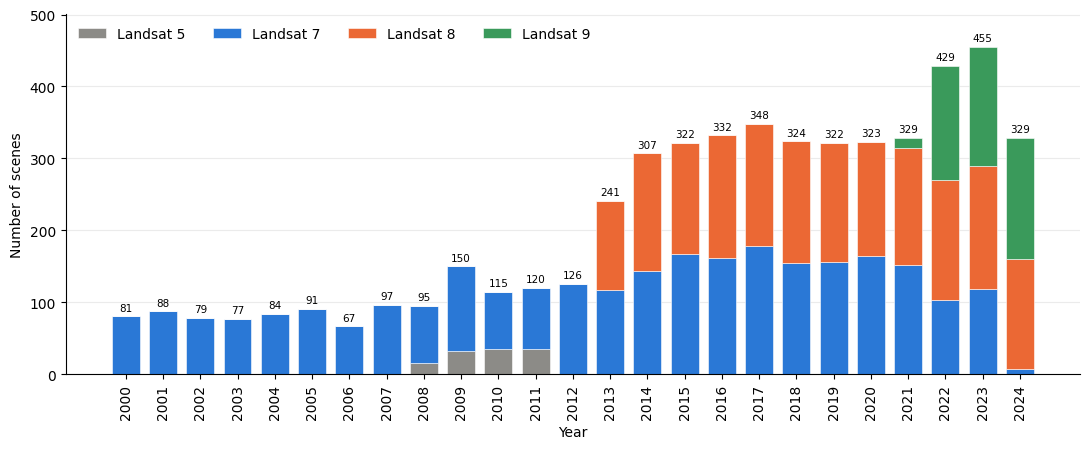

In [2]:
# ------------------------------------------------------------
# Table S1, Table S2 and Figure S2 from the GEE processing log
# ------------------------------------------------------------
xls = pd.ExcelFile(SENSOR_LOG_XLSX)
print("Tabs in the workbook:", xls.sheet_names)
if SENSOR_LOG_SHEET not in xls.sheet_names:
    raise KeyError(f"Tab {SENSOR_LOG_SHEET!r} not found; available: {xls.sheet_names}")
log = pd.read_excel(xls, sheet_name=SENSOR_LOG_SHEET)
log.columns = log.columns.str.strip()

needed = ["year", "scene_count", "l5_count", "l7_count", "l8_count", "l9_count",
          "l7_share_of_scenes", "gap_filled", "Otsu_Raw", "otsu_Oper_threshold"]
missing = [c for c in needed if c not in log.columns]
if missing:
    raise KeyError(f"Columns missing from {SENSOR_LOG_SHEET}: {missing}\nFound: {log.columns.tolist()}")
log = log.sort_values("year").reset_index(drop=True)
assert len(log) == 25 and log["year"].tolist() == list(range(2000, 2025))

counts = log[["l5_count", "l7_count", "l8_count", "l9_count"]].astype(int)
assert (counts.sum(axis=1) == log["scene_count"].astype(int)).all(), "Sensor counts do not add up to scene_count"

table_s1 = pd.DataFrame({
    "Year": log["year"].astype(int),
    "L5": counts["l5_count"],
    "L7": counts["l7_count"],
    "L8": counts["l8_count"],
    "L9": counts["l9_count"],
    "Total scenes": log["scene_count"].astype(int),
    "L7 share (%)": (log["l7_share_of_scenes"] * 100).round(1),
    "Gap fill": np.where(log["gap_filled"].astype(int) == 1, "Yes", "No"),
    "Raw Otsu T": log["Otsu_Raw"].round(3),
    "Operational T": log["otsu_Oper_threshold"].round(3),
})
total = {"Year": "Total", "L5": table_s1.L5.sum(), "L7": table_s1.L7.sum(), "L8": table_s1.L8.sum(),
         "L9": table_s1.L9.sum(), "Total scenes": table_s1["Total scenes"].sum()}
table_s1 = pd.concat([table_s1, pd.DataFrame([total])], ignore_index=True)
display(table_s1)
sensor_composition = log[["year"] + list(counts.columns)].copy()
sensor_composition.to_csv(OUTPUT_DIR / "sensor_composition_by_year_from_log.csv", index=False)
save_table(table_s1, "Table_S1_Annual_Landsat_sensor_composition_and_thresholds")

# Table S2: sensor and band definitions (as in the GEE script) with scene totals from the log
years_used = {s: log.loc[counts[c] > 0, "year"].astype(int).tolist()
              for s, c in [("Landsat 5", "l5_count"), ("Landsat 7", "l7_count"),
                           ("Landsat 8", "l8_count"), ("Landsat 9", "l9_count")]}

def year_ranges(years):
    out, start = [], None
    for i, y in enumerate(years):
        if start is None:
            start = y
        if i == len(years) - 1 or years[i + 1] != y + 1:
            out.append(f"{start}" if start == y else f"{start}–{y}")
            start = None
    return ", ".join(out)

table_s2 = pd.DataFrame([
    ["Landsat 5", "TM", "LANDSAT/LT05/C02/T1_L2", "SR_B2", "SR_B4", "SR_B5", "SR_B7", "l5_count"],
    ["Landsat 7", "ETM+", "LANDSAT/LE07/C02/T1_L2", "SR_B2", "SR_B4", "SR_B5", "SR_B7", "l7_count"],
    ["Landsat 8", "OLI", "LANDSAT/LC08/C02/T1_L2", "SR_B3", "SR_B5", "SR_B6", "SR_B7", "l8_count"],
    ["Landsat 9", "OLI-2", "LANDSAT/LC09/C02/T1_L2", "SR_B3", "SR_B5", "SR_B6", "SR_B7", "l9_count"],
], columns=["Sensor", "Instrument", "GEE collection", "Green", "NIR", "SWIR1", "SWIR2", "_col"])
table_s2.insert(3, "Years contributing", table_s2["Sensor"].map(lambda s: year_ranges(years_used[s])))
table_s2["Scenes"] = table_s2["_col"].map(lambda c: int(counts[c].sum()))
table_s2 = table_s2.drop(columns="_col")
display(table_s2)
save_table(table_s2, "Table_S2_Landsat_sensors_bands_and_scene_counts")

# Figure S2: stacked sensor composition with annual totals
colours = {"Landsat 5": "#8c8b87", "Landsat 7": "#2a78d6", "Landsat 8": "#eb6834", "Landsat 9": "#3a9a5b"}
fig, ax = plt.subplots(figsize=(11, 4.6))
bottom = np.zeros(len(log))
for sensor, col in [("Landsat 5", "l5_count"), ("Landsat 7", "l7_count"),
                    ("Landsat 8", "l8_count"), ("Landsat 9", "l9_count")]:
    ax.bar(log["year"].astype(int), counts[col], bottom=bottom, color=colours[sensor],
           label=sensor, width=0.75, edgecolor="white", linewidth=0.4)
    bottom += counts[col].to_numpy()
for x, t in zip(log["year"].astype(int), bottom):
    ax.text(x, t + 5, f"{int(t)}", ha="center", va="bottom", fontsize=7.5)
ax.set_xlabel("Year")
ax.set_ylabel("Number of scenes")
ax.set_xticks(range(2000, 2025))
ax.tick_params(axis="x", rotation=90)
ax.set_ylim(0, bottom.max() * 1.1)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=4, loc="upper left")
fig.tight_layout()
save_figure(fig, "Figure_S2_Landsat_sensor_composition")
plt.show()



## 3. Load and inspect the Landsat scene metadata

Required fields (as actually present in `scene_metadata_full_2000_2024.csv`):
`year`, `sensor`, `landsat_product_id`, `time_start_iso`, `cloud_cover`.

This section prints a metadata summary and displays the first records.


In [3]:
if not RUN_SCENE_SECTIONS:
    print("Skipped (load scene metadata): scene metadata CSV not found.")
else:

    REQUIRED_SCENE_COLUMNS = [
        "year",
        "sensor",
        "landsat_product_id",
        "time_start_iso",
        "cloud_cover",
    ]

    def load_scene_metadata(path=SCENE_METADATA_FILE):
        path = Path(path)

        if not path.exists():
            raise FileNotFoundError(f"Scene metadata file not found:\n{path}")

        df = pd.read_csv(path)

        missing = [c for c in REQUIRED_SCENE_COLUMNS if c not in df.columns]
        if missing:
            raise KeyError(
                "Missing required scene metadata columns: "
                + ", ".join(missing)
                + f"\nAvailable columns: {df.columns.tolist()}"
            )

        out = df[REQUIRED_SCENE_COLUMNS].copy()

        out["year"] = pd.to_numeric(out["year"], errors="coerce").astype("Int64")
        out["cloud_cover"] = pd.to_numeric(out["cloud_cover"], errors="coerce")
        out["acquisition_datetime"] = pd.to_datetime(
            out["time_start_iso"], errors="coerce", utc=True
        )

        out = (
            out.dropna(subset=["year", "landsat_product_id", "acquisition_datetime"])
            .sort_values("acquisition_datetime")
            .reset_index(drop=True)
        )

        return out


    scenes = load_scene_metadata()

    print("Scene metadata loaded successfully")
    print("----------------------------------")
    print("Rows         :", len(scenes))
    print("Unique scenes:", scenes["landsat_product_id"].nunique())
    print("Years        :", scenes["year"].min(), "to", scenes["year"].max())
    print("Unique years :", scenes["year"].nunique())
    print("Sensors      :", sorted(scenes["sensor"].dropna().unique().tolist()))
    print(
        "Date range   :",
        scenes["acquisition_datetime"].min(),
        "to",
        scenes["acquisition_datetime"].max(),
    )

    print("\nFirst 10 records")
    display(scenes.head(10))


Scene metadata loaded successfully
----------------------------------
Rows         : 5332
Unique scenes: 5332
Years        : 2000 to 2024
Unique years : 25
Sensors      : ['L5', 'L7', 'L8', 'L9']
Date range   : 2000-01-15 07:17:27+00:00 to 2024-12-26 07:25:05+00:00

First 10 records


,year,sensor,landsat_product_id,time_start_iso,cloud_cover,acquisition_datetime
0,2000,L7,LE07_L2SP_165061_20000115_20200918_02_T1,2000-01-15T07:17:27,9.0,2000-01-15 07:17:27+00:00
1,2000,L7,LE07_L2SP_165062_20000115_20200918_02_T1,2000-01-15T07:17:51,28.0,2000-01-15 07:17:51+00:00
2,2000,L7,LE07_L2SP_166061_20000122_20200918_02_T1,2000-01-22T07:23:37,27.0,2000-01-22 07:23:37+00:00
3,2000,L7,LE07_L2SP_166062_20000122_20200918_02_T1,2000-01-22T07:24:01,7.0,2000-01-22 07:24:01+00:00
4,2000,L7,LE07_L2SP_166063_20000122_20200918_02_T1,2000-01-22T07:24:25,11.0,2000-01-22 07:24:25+00:00
5,2000,L7,LE07_L2SP_167061_20000129_20200918_02_T1,2000-01-29T07:29:48,37.0,2000-01-29 07:29:48+00:00
6,2000,L7,LE07_L2SP_167062_20000129_20200918_02_T1,2000-01-29T07:30:12,35.0,2000-01-29 07:30:12+00:00
7,2000,L7,LE07_L2SP_165062_20000131_20200918_02_T1,2000-01-31T07:17:50,23.0,2000-01-31 07:17:50+00:00
8,2000,L7,LE07_L2SP_166061_20000223_20200918_02_T1,2000-02-23T07:23:25,6.0,2000-02-23 07:23:25+00:00
9,2000,L7,LE07_L2SP_167061_20000301_20200918_02_T1,2000-03-01T07:29:38,18.0,2000-03-01 07:29:38+00:00



### 3.1 Scene metadata quality checks and visualisation

These checks help confirm that the scene metadata covers the expected
years and that duplicate scene identifiers have not been introduced.


Scene metadata quality summary
------------------------------


,value
rows,5332
unique_scene_ids,5332
duplicate_scene_ids,0
unique_years,25
first_year,2000
last_year,2024
missing_cloud_cover,0


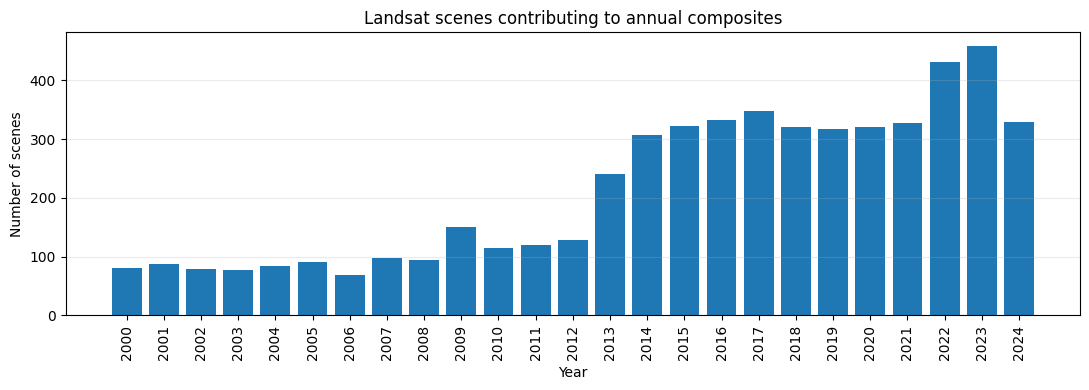


Sensor contribution by year


sensor,L5,L7,L8,L9
year,,,,
2000,0,81,0,0
2001,0,88,0,0
2002,0,79,0,0
2003,1,76,0,0
2004,0,84,0,0
2005,0,91,0,0
2006,0,69,0,0
2007,1,97,0,0
2008,16,79,0,0


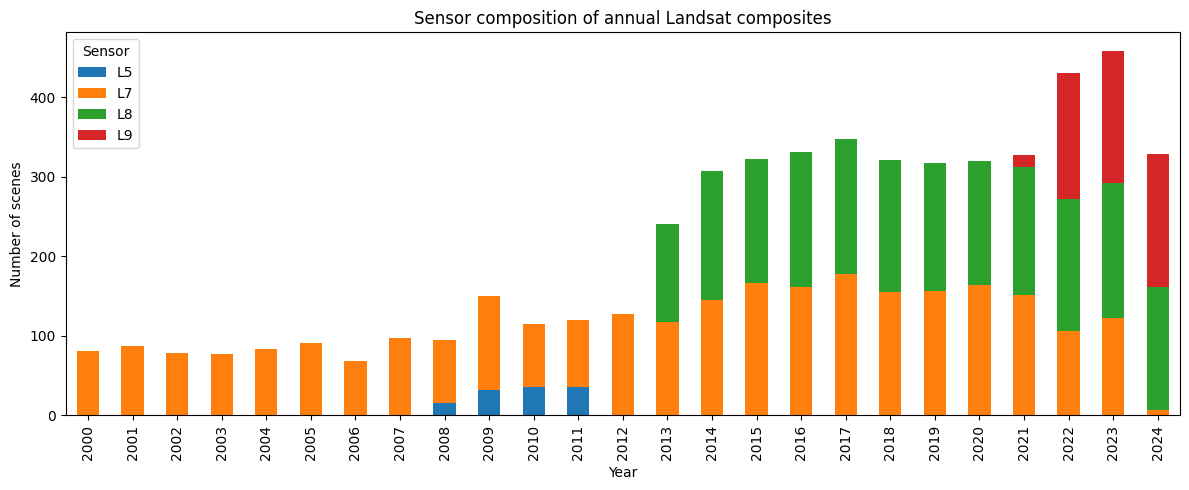


All outputs written to: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Landsat_sensor_summary


In [4]:
if not RUN_SCENE_SECTIONS:
    print("Skipped (scene QC): scene metadata CSV not found.")
else:

    scene_qc = pd.Series({
        "rows": len(scenes),
        "unique_scene_ids": scenes["landsat_product_id"].nunique(),
        "duplicate_scene_ids": int(scenes["landsat_product_id"].duplicated().sum()),
        "unique_years": scenes["year"].nunique(),
        "first_year": scenes["year"].min(),
        "last_year": scenes["year"].max(),
        "missing_cloud_cover": int(scenes["cloud_cover"].isna().sum()),
    })

    print("Scene metadata quality summary")
    print("------------------------------")
    display(scene_qc.to_frame("value"))
    scene_qc.to_frame("value").to_csv(OUTPUT_DIR / "scene_metadata_quality_summary.csv")

    # Number of contributing scenes per year
    scenes_per_year = scenes.groupby("year").size()
    scenes_per_year.to_frame("n_scenes").to_csv(OUTPUT_DIR / "scenes_per_year.csv")

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(scenes_per_year.index.astype(str), scenes_per_year.values)
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of scenes")
    ax.set_title("Landsat scenes contributing to annual composites")
    ax.tick_params(axis="x", rotation=90)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "scenes_per_year.jpg", dpi=200, pil_kwargs={"quality": 95})
    plt.show()

    # Sensor composition by year
    sensor_year = (
        scenes.groupby(["year", "sensor"])
        .size()
        .unstack(fill_value=0)
    )
    sensor_year.to_csv(OUTPUT_DIR / "sensor_composition_by_year.csv")

    print("\nSensor contribution by year")
    display(sensor_year)

    ax = sensor_year.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 5)
    )
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of scenes")
    ax.set_title("Sensor composition of annual Landsat composites")
    ax.legend(title="Sensor")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "sensor_composition_by_year.jpg", dpi=200, pil_kwargs={"quality": 95})
    plt.show()

    print(f"\nAll outputs written to: {OUTPUT_DIR}")


## 4. Year x geometric_rmse_model - majority/plurality sensor table

In [5]:
if not RUN_SCENE_SECTIONS:
    print("Skipped (RMSE_y table): scene metadata CSV not found.")
else:

    rmse_df = pd.read_csv(SCENE_METADATA_FILE)

    required = ["year", "sensor", "geometric_rmse_model"]
    missing = [c for c in required if c not in rmse_df.columns]
    if missing:
        raise KeyError(f"Missing columns: {missing}\nAvailable: {rmse_df.columns.tolist()}")

    by_year_sensor = rmse_df.groupby(["year", "sensor"]).agg(
        n_scenes=("geometric_rmse_model", "count"),
        mean_rmse=("geometric_rmse_model", "mean")
    ).reset_index()

    idx = by_year_sensor.groupby("year")["n_scenes"].idxmax()
    majority = by_year_sensor.loc[idx].reset_index(drop=True)

    totals = rmse_df.groupby("year").size().rename("total_scenes")
    majority = majority.merge(totals, on="year")
    majority["majority_share_pct"] = (majority["n_scenes"] / majority["total_scenes"] * 100).round(1)

    # True majority (>50%) vs. merely the largest group (plurality) - some
    # years (e.g. 2022, 2023) are 3-way splits where the "leading" sensor
    # doesn't actually clear 50%. Check this before trusting the table.
    majority["true_majority"] = majority["majority_share_pct"] > 50.0

    majority = majority.rename(columns={
        "sensor": "majority_sensor",
        "n_scenes": "majority_sensor_scenes",
        "mean_rmse": "geometric_rmse_model"
    })[[
        "year", "majority_sensor", "majority_sensor_scenes", "total_scenes",
        "majority_share_pct", "true_majority", "geometric_rmse_model"
    ]]

    majority["geometric_rmse_model"] = majority["geometric_rmse_model"].round(3)
    majority = majority.sort_values("year").reset_index(drop=True)

    display(majority)

    print(f"\nYears without a true majority (<=50%): "
          f"{majority.loc[~majority['true_majority'], 'year'].tolist()}")

    majority.to_csv(OUTPUT_DIR / "year_geometric_rmse_majority_sensor.csv", index=False)
    print(f"Wrote {OUTPUT_DIR / 'year_geometric_rmse_majority_sensor.csv'}")

,year,majority_sensor,majority_sensor_scenes,total_scenes,majority_share_pct,true_majority,geometric_rmse_model
0,2000,L7,81,81,100.0,True,5.069
1,2001,L7,88,88,100.0,True,4.947
2,2002,L7,79,79,100.0,True,4.838
3,2003,L7,76,77,98.7,True,4.995
4,2004,L7,84,84,100.0,True,5.225
5,2005,L7,91,91,100.0,True,5.028
6,2006,L7,69,69,100.0,True,4.950
7,2007,L7,97,98,99.0,True,5.442
8,2008,L7,79,95,83.2,True,5.068
9,2009,L7,118,150,78.7,True,4.931



Years without a true majority (<=50%): [2021, 2022, 2023]
Wrote D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Landsat_sensor_summary\year_geometric_rmse_majority_sensor.csv
